# 03 - Cohort retention

**Goal:** measure how well customers stay active after their first purchase, compare cohorts, and investigate why new-customer acquisition fell in 2011.

**Input:** `data/processed/transactions_clean.csv`
**Output:** `data/processed/cohort_retention.csv`, `data/processed/cohort_summary.csv`

**Definitions**
- *Cohort* = month of a customer's first purchase.
- *Month k* = k months after the cohort month. A customer is *retained in month k* if they placed at least one order in that month.
- Only tracked customers (with a customer ID) are included. December 2011 is a partial month and is excluded.

**Caveat:** the data starts in Dec 2009, so the Dec 2009 cohort includes customers who had already bought before the window. Its retention is overstated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150)

In [2]:
df = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    parse_dates=["invoice_date", "invoice_month", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": str, "customer_id": "Int64"},
)
sales = df[~df.is_cancellation]
cancels = df[df.is_cancellation]
tracked = sales[sales.has_customer]  # customer-level analysis only

LAST_FULL_MONTH = pd.Timestamp("2011-11-01")  # data ends 9 Dec 2011 (partial month)

## 1. Build the retention matrix

In [3]:
activity = (
    tracked[tracked.invoice_month <= LAST_FULL_MONTH]
    .groupby(["customer_id", "invoice_month"], as_index=False)
    .agg(cohort=("first_purchase_month", "first"))
)
activity["k"] = (
    (activity.invoice_month.dt.year - activity.cohort.dt.year) * 12
    + (activity.invoice_month.dt.month - activity.cohort.dt.month)
)

counts = activity.groupby(["cohort", "k"]).customer_id.nunique().unstack()

# A cell is observable only if cohort + k <= last full month. Unobservable cells stay NaN; observable empty cells become 0.
max_k = ((LAST_FULL_MONTH.year - counts.index.year) * 12 + (LAST_FULL_MONTH.month - counts.index.month))
observable = pd.DataFrame(
    {k: k <= max_k for k in counts.columns}, index=counts.index
)
counts = counts.where(observable)
counts = counts.mask(observable & counts.isna(), 0)

cohort_size = counts[0]
retention = counts.div(cohort_size, axis=0)
cohort_size.to_frame("customers").T

cohort,2009-12-01,2010-01-01,2010-02-01,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,...,2011-02-01,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01
customers,955.00,383.00,374.00,443.00,294.00,254.00,270.00,186.00,162.00,243.00,...,124.00,179.00,106.00,111.00,108.00,102.00,106.00,189.00,221.00,191.00


## 2. Retention heatmap

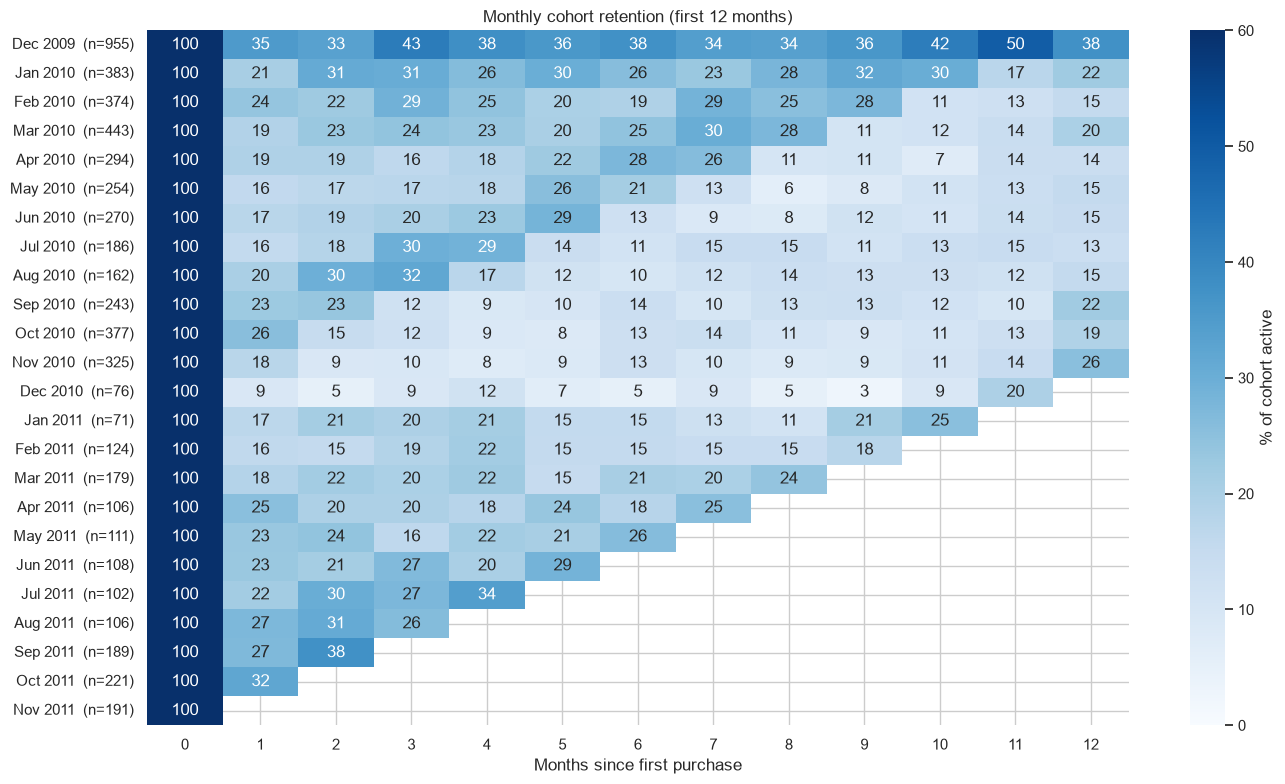

In [4]:
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(
    retention.iloc[:, :13] * 100,
    annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=60,
    cbar_kws={"label": "% of cohort active"}, ax=ax,
)
ax.set_yticklabels([f"{c:%b %Y}  (n={int(cohort_size[c]):,})" for c in retention.index], rotation=0)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("")
ax.set_title("Monthly cohort retention (first 12 months)")
save(fig, "03_cohort_heatmap")
plt.show()

## 3. Compare cohort groups

Weighted retention at months 1, 3, 6 and 12, using only cohorts old enough to observe each point. Groups: the first cohort (left-censored), 2010 H1, 2010 H2, 2011 H1.

In [5]:
def group(cohort):
    if cohort == pd.Timestamp("2009-12-01"):
        return "Dec 2009 (left-censored)"
    return f"{cohort.year} H{1 if cohort.month <= 6 else 2}"

groups = pd.Series([group(c) for c in counts.index], index=counts.index)

def weighted_retention(k):
    obs = counts[k].notna()
    return counts.loc[obs, k].groupby(groups[obs]).sum() / cohort_size[obs].groupby(groups[obs]).sum()

summary = pd.DataFrame({f"month {k}": weighted_retention(k) for k in (1, 3, 6, 12)})
summary.insert(0, "customers", cohort_size.groupby(groups).sum().astype(int))
summary

,customers,month 1,month 3,month 6,month 12
2010 H1,2018,0.20,0.24,0.22,0.17
2010 H2,1369,0.20,0.16,0.12,0.20
2011 H1,699,0.20,0.20,0.19,NaN
2011 H2,809,0.28,0.27,NaN,NaN
Dec 2009 (left-censored),955,0.35,0.43,0.38,0.38


Month-by-month activity is **seasonal**: a customer first acquired in Oct 2010 is much more likely to be active in Oct 2011 (month 12) than in May 2011 (month 7). Monthly retention therefore mixes churn with seasonal ordering rhythm.

A fairer measure for a business whose median reorder gap is about a month is the **90-day repeat rate**: the share of new customers who place a second order within 90 days of their first.

In [6]:
orders = (
    tracked.groupby(["customer_id", "invoice"]).invoice_date.min().reset_index()
    .sort_values(["customer_id", "invoice_date"])
)
per_customer = pd.DataFrame({
    "first": orders.groupby("customer_id").invoice_date.min(),
    "second": orders.groupby("customer_id").invoice_date.apply(lambda s: s.iloc[1] if len(s) > 1 else pd.NaT),
})
per_customer["days_to_second"] = (per_customer.second - per_customer["first"]).dt.total_seconds() / 86400
per_customer["group"] = per_customer["first"].dt.to_period("M").dt.to_timestamp().map(groups)

# Only customers whose first order is at least 90 days before the end of the data
data_end = df.invoice_date.max()
eligible = per_customer[per_customer["first"] <= data_end - pd.Timedelta(days=90)].copy()
eligible["repeat_90d"] = eligible.days_to_second <= 90

repeat_90 = eligible.groupby("group").agg(customers=("repeat_90d", "size"), repeat_rate_90d=("repeat_90d", "mean"))
repeat_90

,customers,repeat_rate_90d
group,,
2010 H1,2018,0.45
2010 H2,1369,0.41
2011 H1,699,0.41
2011 H2,240,0.56
Dec 2009 (left-censored),955,0.61


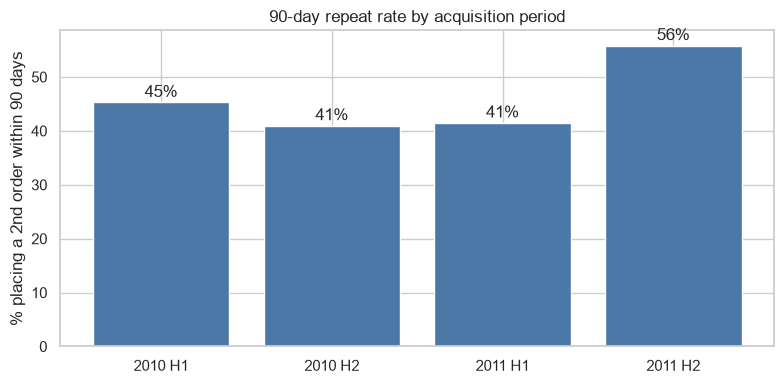

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
order = ["2010 H1", "2010 H2", "2011 H1", "2011 H2"]
r = repeat_90.reindex([g for g in order if g in repeat_90.index])
ax.bar(r.index, r.repeat_rate_90d * 100, color="#4C78A8")
for x, v in zip(r.index, r.repeat_rate_90d * 100):
    ax.text(x, v + 1, f"{v:.0f}%", ha="center")
ax.set_ylabel("% placing a 2nd order within 90 days")
ax.set_title("90-day repeat rate by acquisition period")
save(fig, "03_repeat_rate_90d")
plt.show()

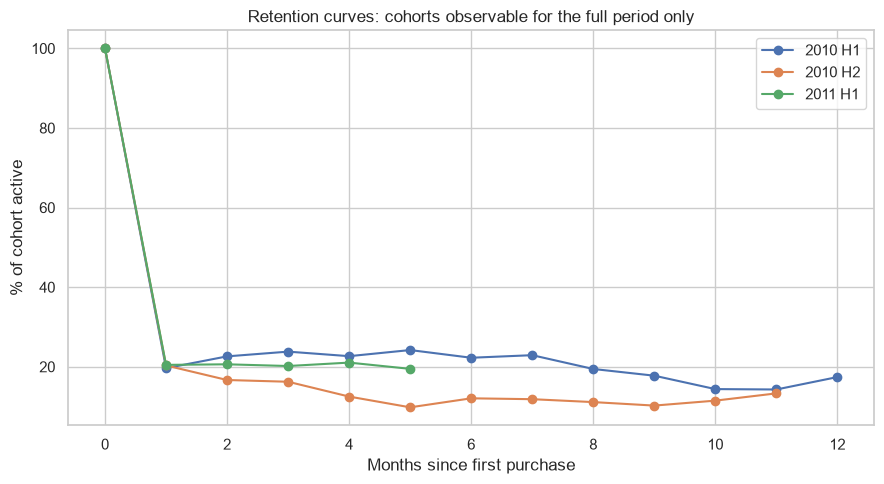

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in ["2010 H1", "2010 H2", "2011 H1"]:
    members = groups[groups == name].index
    curve = counts.loc[members].sum() / np.where(counts.loc[members].notna().all(), cohort_size[members].sum(), np.nan)
    curve = curve.iloc[:13]
    ax.plot(curve.index, curve * 100, marker="o", label=name)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("% of cohort active")
ax.set_title("Retention curves: cohorts observable for the full period only")
ax.legend()
save(fig, "03_retention_curves")
plt.show()

## 4. Does the acquisition month matter?

Customers acquired in the Sep-Nov peak may be one-season buyers. Compare 6-month retention of peak-season cohorts with the rest.

In [9]:
season = np.where(counts.index.month.isin([9, 10, 11]), "Sep-Nov cohorts", "other months")
rows = {}
for label in ("Sep-Nov cohorts", "other months"):
    sel = (season == label) & counts[6].notna().to_numpy() & (counts.index != pd.Timestamp("2009-12-01"))
    rows[label] = {
        "cohorts": int(sel.sum()),
        "customers": int(cohort_size[sel].sum()),
        "month 1": counts.loc[sel, 1].sum() / cohort_size[sel].sum(),
        "month 3": counts.loc[sel, 3].sum() / cohort_size[sel].sum(),
        "month 6": counts.loc[sel, 6].sum() / cohort_size[sel].sum(),
    }
pd.DataFrame(rows).T

,cohorts,customers,month 1,month 3,month 6
Sep-Nov cohorts,3.00,945.00,0.22,0.11,0.13
other months,14.00,"3,033.00",0.19,0.23,0.20


## 5. Why did new-customer acquisition fall in 2011?

*5 Whys #1 follow-up.* Compare new customers by month, by country and by size of first order.

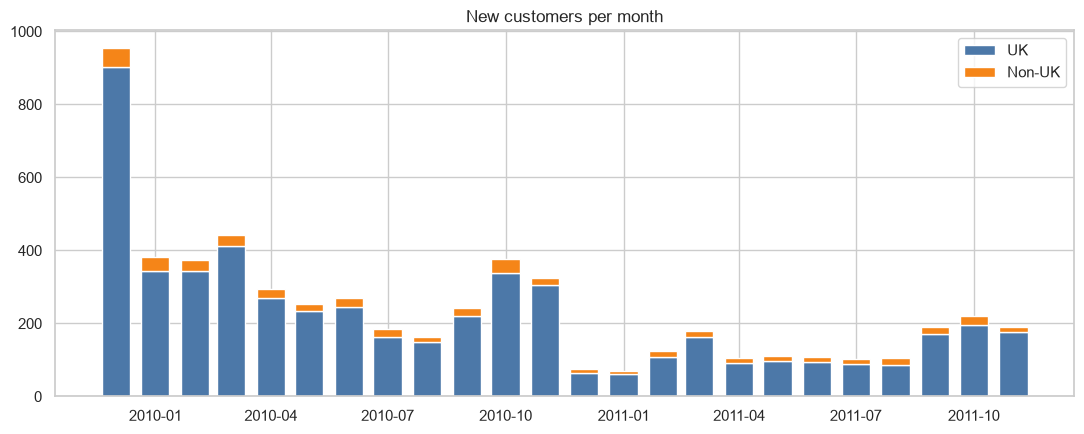

In [10]:
first_orders = (
    tracked.sort_values("invoice_date")
    .groupby("customer_id")
    .agg(first_invoice=("invoice", "first"), country=("country", "first"), cohort=("first_purchase_month", "first"))
)
first_value = tracked.groupby(["customer_id", "invoice"]).line_total.sum().rename("first_order_value").reset_index()
first_orders = first_orders.reset_index().merge(
    first_value, left_on=["customer_id", "first_invoice"], right_on=["customer_id", "invoice"]
).set_index("customer_id")
first_orders["year"] = first_orders.cohort.dt.year
first_orders["uk"] = np.where(first_orders.country == "United Kingdom", "UK", "Non-UK")

new_by_month = first_orders[first_orders.cohort <= LAST_FULL_MONTH].groupby(["cohort", "uk"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(new_by_month.index, new_by_month["UK"], width=22, label="UK", color="#4C78A8")
ax.bar(new_by_month.index, new_by_month["Non-UK"], width=22, bottom=new_by_month["UK"], label="Non-UK", color="#F58518")
ax.set_title("New customers per month")
ax.legend()
save(fig, "03_new_customers_per_month")
plt.show()

In [11]:
window = first_orders[(first_orders.cohort.dt.month.between(6, 11)) & first_orders.year.isin([2010, 2011])]
comparison = window.groupby(["year", "uk"]).size().unstack()
comparison["total"] = comparison.sum(axis=1)
print(comparison)

print()
print("First-order value (GBP), Jun-Nov cohorts:")
window.groupby("year").first_order_value.describe()[["count", "25%", "50%", "75%", "mean"]]

uk    Non-UK    UK  total
year                     
2010     141  1422   1563
2011     106   811    917

First-order value (GBP), Jun-Nov cohorts:


,count,25%,50%,75%,mean
year,,,,,
2010,"1,563.00",162.03,280.87,435.19,431.73
2011,917.00,166.03,300.34,455.17,391.68


## 6. Save outputs for the dashboard

In [12]:
long = (
    retention.stack().rename("retention").reset_index()
    .rename(columns={"level_1": "k"})
    .merge(cohort_size.rename("cohort_size").reset_index(), on="cohort")
)
long.to_csv(PROCESSED_DIR / "cohort_retention.csv", index=False)
summary.reset_index(names="group").to_csv(PROCESSED_DIR / "cohort_summary.csv", index=False)
new_by_month.reset_index().to_csv(PROCESSED_DIR / "new_customers_by_month.csv", index=False)
repeat_90.reset_index().to_csv(PROCESSED_DIR / "repeat_rate_90d.csv", index=False)
print(f"saved {len(long):,} cohort rows")

saved 576 cohort rows


## 7. Key takeaways

| Finding | Evidence |
|---|---|
| Cohort quality has been stable since mid-2010 | Month-1 activity is ~20% for 2010 H1, 2010 H2 and 2011 H1 cohorts. The 90-day repeat rate is 45%, 41% and 41%: a drop of about four points between the halves of 2010 (p = 0.013, notebook 11), then no change (p = 0.82). Part of that drop may be left-censoring, because early-2010 'new' customers can include earlier buyers |
| Retention is seasonal | The 2010 H2 cohorts are *more* active at month 12 (20%) than at month 6 (12%) because they return for the next Q4 peak. Monthly retention mixes churn with ordering rhythm |
| Peak-season customers are weaker | Sep-Nov cohorts: 22% active at month 1 but 11% at month 3 and 13% at month 6, against 19% / 23% / 20% for other months (only 3 peak cohorts, so treat as indicative) |
| Acquisition volume fell; quality has been flat since mid-2010 | Jun-Nov new customers: UK 1,422 to 811 (-43%), non-UK 141 to 106 (-25%). Median first-order value was £281 in 2010 and £300 in 2011 |
| The data cannot explain the acquisition drop | There is no channel, marketing or web-traffic data. This needs an external answer |

### Updated 5 Whys #1
Sales are flat while fewer new customers arrive. Cohort quality has been stable since mid-2010 (the 90-day repeat rate fell about four points in 2010 and then held), and acquisition fell about 41% (Jun-Nov, 95% interval -46% to -36%; 2011 was lower in all six months, notebook 11). New-customer sales fell while returning-customer sales grew, which fits the flat total, but the data cannot show that one caused the other or why acquisition fell.

### Caveats
- The Dec 2009 cohort is left-censored and overstated (35-43% retention).
- Month-12 and later cells exist only for 2010 cohorts; 2011 cohorts are still maturing.
- Groups at different horizons cover different sets of cohorts (e.g. 2010 H2 at month 12 is Jul-Nov 2010 only).
- The 2010 H1 repeat rate (45%) may be inflated by left-censoring, so the H1-to-H2 drop is an upper bound on any real decline.